# PRML 6 — Gaussian Mixture Data, K-Means, and Classification

This notebook demonstrates 2D Gaussian-mixture generation, K-Means clustering, and distortion-based classification. The original sections show the workflow for a selected covariance case; the final section runs the complete experiment for **all three cases: isotropic, diagonal, and full covariance**, and compares their test-set performance.

Run the notebook from top to bottom.

## 1. Imports, random-number generation, and Gaussian sampling

Import NumPy and Matplotlib, initialize the seed, and define the custom pseudo-random and Gaussian-generation functions. These functions are used by the later data-generation cell.

In [18]:
from math import log
import matplotlib.pyplot as plt
import numpy as np
seed=42
def myRandom():
  global seed
  a = 1664525
  c = 1013904223
  m = 2**32
  seed=(a*seed+c)%m
  return seed/m
def myUniform(a,b):
  return a+(b-a)*myRandom()
# Generate Gaussian random values using polar method
def gaussian(mu, sigma, n):
    g = []
    while len(g) < n:
        u1 = myUniform(-1, 1)
        u2 = myUniform(-1, 1)
        s = u1 * u1 + u2 * u2
        if s > 0 and s < 1:
            k = (-2 * log(s) / s) ** 0.5
            x = u1 * k
            y = u2 * k
            g.append(mu + sigma * x)
            if len(g) < n:
                g.append(mu + sigma * y)
    return g

## 2. Generate the two classes

Set the number of samples, select the covariance case, and define the three Gaussian-component means and mixture weights for each class. The cell generates the component samples and combines them into the class datasets.

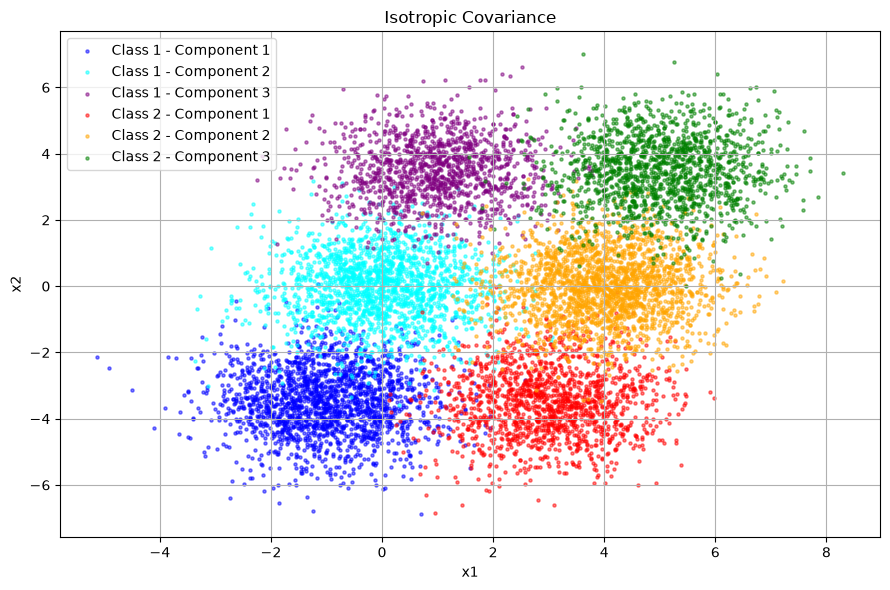

Class 1 points: 5000
Class 2 points: 5000


In [ ]:
n = 5000
case = 1  # 1 = Isotropic, 2 = Diagonal, 3 = Full
# Three Gaussian components for each class
means_class1 = [[-1.0, -3.5],
                [ 0.0,  0.0],
                [ 1.0,  3.5]]

means_class2 = means_class1 + np.array([[ 4.0, 0.0]])

# Mixture weights
weights_class1 = [0.40, 0.35, 0.25]
weights_class2 = [0.30, 0.40, 0.30]
# Covariance matrices
isotropic_cov = np.array([
    [1, 0],
    [0, 1]
])
diagonal_cov = np.array([
    [4, 0],
    [0, 1]
])
full_cov = np.array([
    [2, 0.8],
    [0.8, 1.5]
])
# 1. Isotropic covariance
def generate_isotropic(mu, sigma, N):
    x1 = gaussian(mu[0], sigma, N)
    x2 = gaussian(mu[1], sigma, N)
    return np.column_stack((x1, x2))
# 2. Diagonal covariance
def generate_diagonal(mu, sigma_x, sigma_y, N):
    x1 = gaussian(mu[0], sigma_x, N)
    x2 = gaussian(mu[1], sigma_y, N)
    return np.column_stack((x1, x2))
# 3. Full covariance
def generate_full(mu, cov, N):
    Z = np.column_stack((
        gaussian(0, 1, N),
        gaussian(0, 1, N)
    ))
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    Lambda_sqrt = np.diag(np.sqrt(eigenvalues))
    C_sqrt = eigenvectors @ Lambda_sqrt @ eigenvectors.T
    return Z @ C_sqrt.T + np.array(mu)
# Generate data using threshold logic
def generate_data(n, weights, means, case):
    components = [[], [], []]
    for _ in range(n):
        u = myRandom()
        if u < weights[0]:
            component = 0
        elif u < weights[0] + weights[1]:
            component = 1
        else:
            component = 2
        components[component].append(1)
    if case == 1:
        c1 = generate_isotropic(
            means[0], 1, len(components[0]))
        c2 = generate_isotropic(
            means[1], 1, len(components[1]))
        c3 = generate_isotropic(
            means[2], 1, len(components[2]))
    elif case == 2:
        c1 = generate_diagonal(
            means[0], 2, 1, len(components[0]))
        c2 = generate_diagonal(
            means[1], 2, 1, len(components[1]))
        c3 = generate_diagonal(
            means[2], 2, 1, len(components[2]))
    elif case == 3:
        c1 = generate_full(
            means[0], full_cov, len(components[0]))
        c2 = generate_full(
            means[1], full_cov, len(components[1]))
        c3 = generate_full(
            means[2], full_cov, len(components[2]))
    else:
        raise ValueError("case must be 1, 2, or 3")
    return c1, c2, c3
# Select covariance type
if case == 1:
    title = "Isotropic Covariance"
elif case == 2:
    title = "Diagonal Covariance"
elif case == 3:
    title = "Full Covariance"
else:
    raise ValueError("case must be 1, 2, or 3")
# Generate three components for each class
c1_component1, c1_component2, c1_component3 = generate_data(
    n, weights_class1, means_class1, case
)
c2_component1, c2_component2, c2_component3 = generate_data(
    n, weights_class2, means_class2, case
)
# Combine components of each class
class1 = np.vstack((
    c1_component1, c1_component2, c1_component3
))
class2 = np.vstack((
    c2_component1, c2_component2, c2_component3
))
# Plot all components
plt.figure(figsize=(9, 6))
plt.scatter(c1_component1[:, 0], c1_component1[:, 1],
            s=5, alpha=0.5, color="blue",
            label="Class 1 - Component 1")
plt.scatter(c1_component2[:, 0], c1_component2[:, 1],
            s=5, alpha=0.5, color="cyan",
            label="Class 1 - Component 2")
plt.scatter(c1_component3[:, 0], c1_component3[:, 1],
            s=5, alpha=0.5, color="purple",
            label="Class 1 - Component 3")
plt.scatter(c2_component1[:, 0], c2_component1[:, 1],
            s=5, alpha=0.5, color="red",
            label="Class 2 - Component 1")
plt.scatter(c2_component2[:, 0], c2_component2[:, 1],
            s=5, alpha=0.5, color="orange",
            label="Class 2 - Component 2")
plt.scatter(c2_component3[:, 0], c2_component3[:, 1],
            s=5, alpha=0.5, color="green",
            label="Class 2 - Component 3")
plt.title(title)
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print("Class 1 points:", len(class1))
print("Class 2 points:", len(class2))

## 3. Inspect the six Gaussian components

Plot histograms for the three components belonging to each class. This gives a quick visual check of how the generated component distributions look.

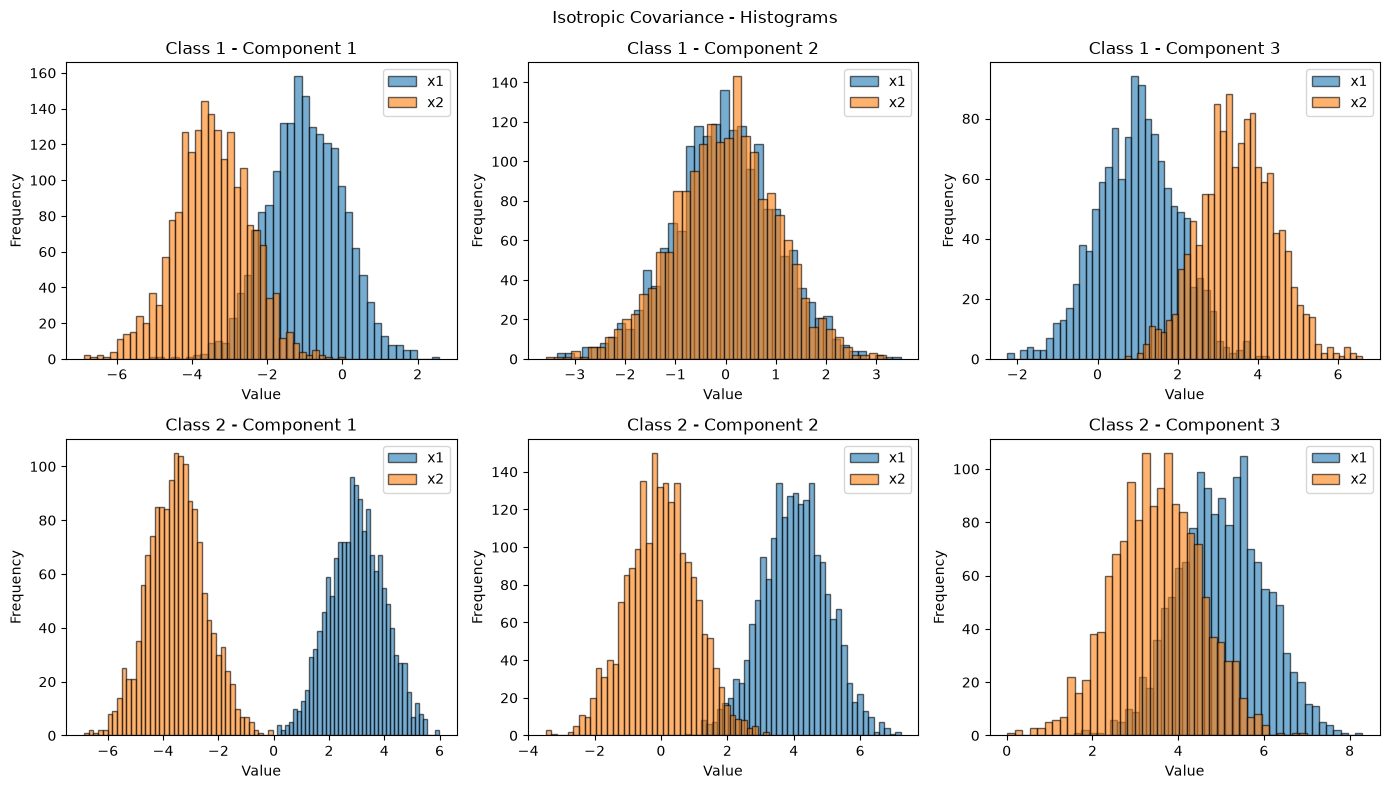

In [20]:
# Bar graphs / histograms for all six components

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

components = [
    (c1_component1, "Class 1 - Component 1"),
    (c1_component2, "Class 1 - Component 2"),
    (c1_component3, "Class 1 - Component 3"),
    (c2_component1, "Class 2 - Component 1"),
    (c2_component2, "Class 2 - Component 2"),
    (c2_component3, "Class 2 - Component 3")
]

for ax, (data, name) in zip(axes.flat, components):
    ax.hist(data[:, 0], bins=40, alpha=0.6,
            label="x1", edgecolor="black")
    ax.hist(data[:, 1], bins=40, alpha=0.6,
            label="x2", edgecolor="black")

    ax.set_title(name)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.suptitle(title + " - Histograms")
plt.tight_layout()
plt.show()

## 4. Split into training and testing sets

Define an 80:20 train/test split and apply it to both classes. The training samples are used to fit K-Means centroids; the test samples are used for evaluation.

In [21]:
# Split data into training and testing sets
def split_data(data):
    indices = np.random.permutation(len(data))
    split_index = int(0.8 * len(data))
    train = data[indices[:split_index]]
    test = data[indices[split_index:]]
    return train, test
train1, test1 = split_data(class1)
train2, test2 = split_data(class2)


## 5. K-Means implementation

Implement K-Means from scratch: initialize centroids, assign samples to their nearest centroid, update centroids, and repeat until convergence or the iteration limit is reached.

In [22]:
# K-means algorithm
def kmeans(data, K, max_iter=100):
    # Step 1: Randomly initialize K centroids
    indices = np.random.choice(len(data), K, replace=False)
    centroids = data[indices].copy()
    for iteration in range(max_iter):
        # Step 2: Assign each point to the nearest centroid
        distances = np.zeros((len(data), K))
        for k in range(K):
            distances[:, k] = np.sum(
                (data - centroids[k]) ** 2, axis=1
            )
        labels = np.argmin(distances, axis=1)
        # Step 3: Reestimate the means
        new_centroids = centroids.copy()
        for k in range(K):
            points = data[labels == k]
            if len(points) > 0:
                new_centroids[k] = np.mean(points, axis=0)
        # Step 4: Repeat until convergence
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break
        centroids = new_centroids
    # Reassign points using the final centroids
    distances = np.zeros((len(data), K))
    for k in range(K):
        distances[:, k] = np.sum(
            (data - centroids[k]) ** 2, axis=1
        )
    labels = np.argmin(distances, axis=1)
    # Calculate distortion
    distortion = 0
    for k in range(K):
        points = data[labels == k]
        distortion += np.sum((points - centroids[k]) ** 2)
    return centroids, labels, distortion
# Apply K-means to the training data of each class
K = 3
centroids1, labels1, distortion1 = kmeans(train1, K)
centroids2, labels2, distortion2 = kmeans(train2, K)
# Display results
print("CLASS 1")
print("Centroids:\n", centroids1)
print("Distortion:", distortion1)
print("\nCLASS 2")
print("Centroids:\n", centroids2)
print("Distortion:", distortion2)

CLASS 1
Centroids:
 [[ 1.00578639e+00  3.51091126e+00]
 [-1.08662965e-02  2.04398440e-03]
 [-1.01647053e+00 -3.47816608e+00]]
Distortion: 7427.442637357288

CLASS 2
Centroids:
 [[ 4.02701451 -0.00590872]
 [ 2.98013544 -3.55678748]
 [ 4.99471915  3.5171104 ]]
Distortion: 7571.069194949381


## 6. Visualize clusters and decision regions

Create a grid over the data range and visualize the regions associated with the learned centroids, alongside the data points and cluster assignments.

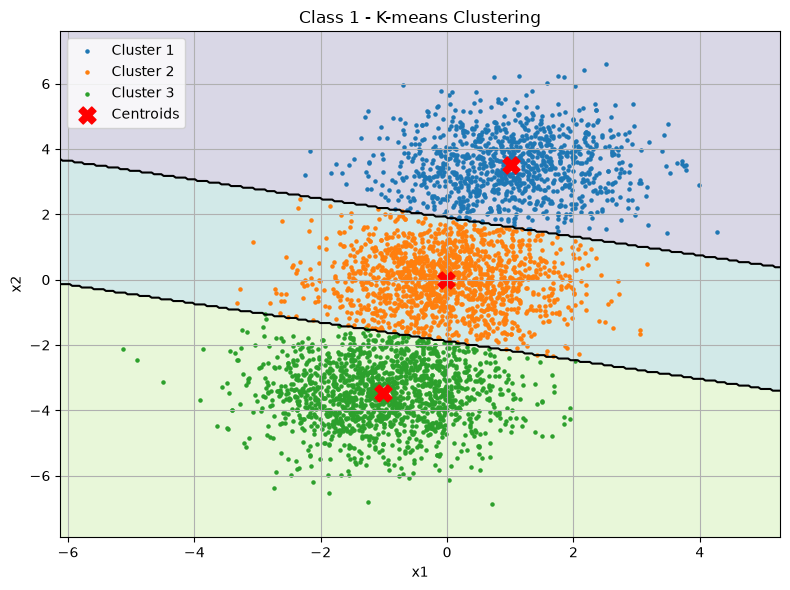

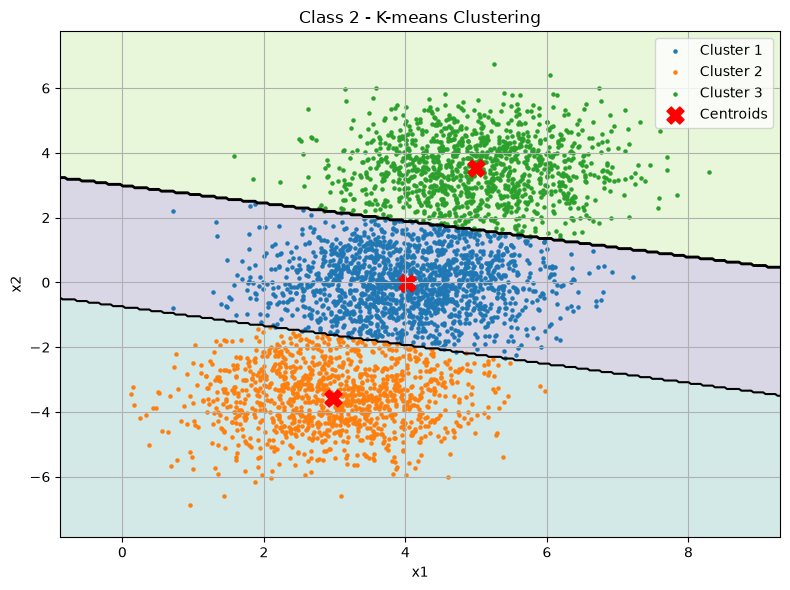

In [23]:
# Plot K-means clusters and boundaries
def plot_clusters(data, centroids, labels, title):

    # Define plotting range
    x_min = data[:, 0].min() - 1
    x_max = data[:, 0].max() + 1
    y_min = data[:, 1].min() - 1
    y_max = data[:, 1].max() + 1

    # Create grid
    x_values = np.linspace(x_min, x_max, 300)
    y_values = np.linspace(y_min, y_max, 300)
    X_grid, Y_grid = np.meshgrid(x_values, y_values)

    grid_points = np.column_stack(
        (X_grid.ravel(), Y_grid.ravel())
    )

    # Assign grid points to nearest centroid
    distances = np.zeros((len(grid_points), len(centroids)))

    for k in range(len(centroids)):
        distances[:, k] = np.sum(
            (grid_points - centroids[k]) ** 2, axis=1
        )

    grid_predictions = np.argmin(distances, axis=1)
    decision_grid = grid_predictions.reshape(X_grid.shape)

    # Plot cluster regions
    plt.figure(figsize=(8, 6))

    plt.contourf(
        X_grid, Y_grid, decision_grid,
        levels=np.arange(len(centroids) + 1) - 0.5,
        alpha=0.2
    )

    # Draw boundaries between clusters
    plt.contour(
        X_grid, Y_grid, decision_grid,
        levels=np.arange(len(centroids) - 1) + 0.5,
        colors="black"
    )

    # Plot data points belonging to each cluster
    for k in range(len(centroids)):
        points = data[labels == k]

        plt.scatter(
            points[:, 0], points[:, 1],
            s=5, label="Cluster " + str(k + 1)
        )

    # Plot centroids
    plt.scatter(
        centroids[:, 0], centroids[:, 1],
        color="red", marker="X", s=150,
        label="Centroids"
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Plot Class 1
plot_clusters(
    train1, centroids1, labels1,
    "Class 1 - K-means Clustering"
)

# Plot Class 2
plot_clusters(
    train2, centroids2, labels2,
    "Class 2 - K-means Clustering"
)

## 7. Classify test samples and evaluate

For each test sample, compare its minimum squared distance to the centroids of Class 1 and Class 2. Predict the class with the smaller distance and calculate the resulting classification performance.

In [24]:

# Predict class for each test sample
def classify_kmeans(data, centroids1, centroids2):

    predictions = []

    for x in data:
        d1 = np.min(np.sum((centroids1 - x) ** 2, axis=1))
        d2 = np.min(np.sum((centroids2 - x) ** 2, axis=1))

        if d1 < d2:
            predictions.append(1)
        else:
            predictions.append(2)

    return np.array(predictions)


pred_test1 = classify_kmeans(test1, centroids1, centroids2)
pred_test2 = classify_kmeans(test2, centroids1, centroids2)

# True labels
true_test1 = np.ones(len(test1), dtype=int)
true_test2 = np.full(len(test2), 2, dtype=int)

# Combine predictions and true labels
predicted_labels = np.concatenate((pred_test1, pred_test2))
true_labels = np.concatenate((true_test1, true_test2))

# Calculate accuracy
correct = np.sum(predicted_labels == true_labels)
total = len(true_labels)
accuracy = (correct / total) * 100

print("\nOverall Classification Results")
print("Correct predictions:", correct)
print("Total test samples:", total)
print("Accuracy:", accuracy, "%")



Overall Classification Results
Correct predictions: 1955
Total test samples: 2000
Accuracy: 97.75 %


## 8. Run the complete experiment for all covariance cases

The cells above demonstrate one selected case. Run this final section to repeat data generation, the 80:20 split, K-Means clustering, cluster-region plots, and distortion-based classification for **isotropic, diagonal, and full covariance**. The results table compares test accuracy and error rate across all three settings.

In [ ]:
# Run the complete experiment for all three covariance configurations.
# Case 1 = Isotropic, Case 2 = Diagonal, Case 3 = Full covariance.

covariance_cases = {
    1: "Isotropic",
    2: "Diagonal",
    3: "Full"
}

all_case_results = []

for case_id, covariance_name in covariance_cases.items():
    print("\n" + "=" * 72)
    print(f"EXPERIMENT: {covariance_name.upper()} COVARIANCE")
    print("=" * 72)

    # Re-create data for this covariance case.
    title = f"{covariance_name} Covariance"
    c1_component1, c1_component2, c1_component3 = generate_data(
        n, weights_class1, means_class1, case_id
    )
    c2_component1, c2_component2, c2_component3 = generate_data(
        n, weights_class2, means_class2, case_id
    )

    class1_case = np.vstack((c1_component1, c1_component2, c1_component3))
    class2_case = np.vstack((c2_component1, c2_component2, c2_component3))

    # Plot the six Gaussian components for this case.
    plt.figure(figsize=(9, 6))
    component_sets = [
        (c1_component1, "Class 1 - Component 1", "blue"),
        (c1_component2, "Class 1 - Component 2", "cyan"),
        (c1_component3, "Class 1 - Component 3", "purple"),
        (c2_component1, "Class 2 - Component 1", "red"),
        (c2_component2, "Class 2 - Component 2", "orange"),
        (c2_component3, "Class 2 - Component 3", "green"),
    ]
    for component_data, component_label, component_color in component_sets:
        plt.scatter(
            component_data[:, 0], component_data[:, 1],
            s=5, alpha=0.5, color=component_color, label=component_label
        )
    plt.title(f"{covariance_name} Covariance - Generated Data")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Perform an independent 80:20 split for each class.
    train1_case, test1_case = split_data(class1_case)
    train2_case, test2_case = split_data(class2_case)

    # Fit K-Means independently to each class's training data.
    K = 3
    centroids1_case, labels1_case, distortion1_case = kmeans(train1_case, K)
    centroids2_case, labels2_case, distortion2_case = kmeans(train2_case, K)

    print(f"Class 1 training distortion: {distortion1_case:.3f}")
    print(f"Class 2 training distortion: {distortion2_case:.3f}")

    # Plot cluster regions and centroids for both classes.
    plot_clusters(
        train1_case, centroids1_case, labels1_case,
        f"{covariance_name} Covariance - Class 1 K-Means"
    )
    plot_clusters(
        train2_case, centroids2_case, labels2_case,
        f"{covariance_name} Covariance - Class 2 K-Means"
    )

    # Classify the held-out samples using minimum squared centroid distance.
    pred_test1_case = classify_kmeans(test1_case, centroids1_case, centroids2_case)
    pred_test2_case = classify_kmeans(test2_case, centroids1_case, centroids2_case)

    true_test1_case = np.ones(len(test1_case), dtype=int)
    true_test2_case = np.full(len(test2_case), 2, dtype=int)

    predictions_case = np.concatenate((pred_test1_case, pred_test2_case))
    true_case = np.concatenate((true_test1_case, true_test2_case))

    correct_case = int(np.sum(predictions_case == true_case))
    total_case = int(len(true_case))
    accuracy_case = 100.0 * correct_case / total_case
    error_rate_case = 100.0 - accuracy_case

    # Confusion matrix rows = true classes, columns = predicted classes.
    confusion_case = np.zeros((2, 2), dtype=int)
    for true_label, predicted_label in zip(true_case, predictions_case):
        confusion_case[true_label - 1, predicted_label - 1] += 1

    print("\nClassification results")
    print("Correct predictions:", correct_case)
    print("Total test samples:", total_case)
    print(f"Accuracy: {accuracy_case:.2f}%")
    print(f"Error rate: {error_rate_case:.2f}%")
    print("Confusion matrix (rows = true class; columns = predicted class):")
    print(confusion_case)

    all_case_results.append({
        "Covariance": covariance_name,
        "Correct": correct_case,
        "Total": total_case,
        "Accuracy (%)": accuracy_case,
        "Error rate (%)": error_rate_case,
        "Confusion matrix": confusion_case
    })

# Summarize performance across the three covariance cases.
print("\n" + "=" * 72)
print("COVARIANCE COMPARISON")
print("=" * 72)
print(f"{'Covariance':<15}{'Correct/Total':<18}{'Accuracy (%)':<16}{'Error rate (%)':<16}")
for result in all_case_results:
    print(
        f"{result['Covariance']:<15}"
        f"{result['Correct']}/{result['Total']:<13}"
        f"{result['Accuracy (%)']:<16.2f}"
        f"{result['Error rate (%)']:<16.2f}"
    )

# Plot accuracy comparison.
plt.figure(figsize=(7, 4.5))
names = [result["Covariance"] for result in all_case_results]
accuracies = [result["Accuracy (%)"] for result in all_case_results]
bars = plt.bar(names, accuracies)
plt.ylim(0, 100)
plt.xlabel("Covariance type")
plt.ylabel("Test accuracy (%)")
plt.title("Distortion-Based Classification Accuracy by Covariance Type")
for bar, value in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 1,
             f"{value:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()
